**Name:** Fahad Irshad

**Reg No:** FA23-BAI-014

# ANN Lab 03 — Perceptron from Scratch & Weight Initialization Study

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.datasets import load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

np.set_printoptions(precision=4, suppress=True)

## Task 1: Dataset Loading and Visualization

Dataset: Breast Cancer Wisconsin (Diagnostic) - sklearn / UCI ML Repository
Shape of X: (569, 30), Shape of y: (569,)
Number of features: 30
Target classes: [np.str_('malignant'), np.str_('benign')]  (0=malignant, 1=benign)
Class counts -> malignant(0): 212, benign(1): 357
Missing values in dataset: 0


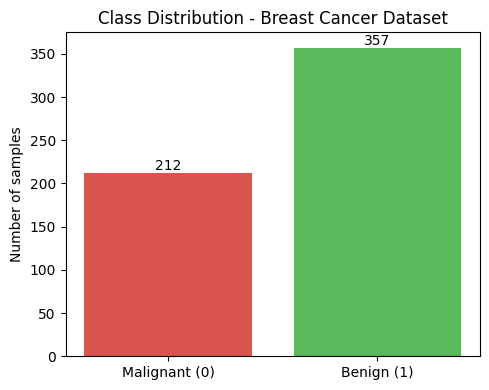

In [2]:
data = load_breast_cancer()
X_raw, y = data.data, data.target

print(f"Dataset: Breast Cancer Wisconsin (Diagnostic) - sklearn / UCI ML Repository")
print(f"Shape of X: {X_raw.shape}, Shape of y: {y.shape}")
print(f"Number of features: {X_raw.shape[1]}")
print(f"Target classes: {list(data.target_names)}  (0=malignant, 1=benign)")
print(f"Class counts -> malignant(0): {(y==0).sum()}, benign(1): {(y==1).sum()}")
print(f"Missing values in dataset: {np.isnan(X_raw).sum()}")

plt.figure(figsize=(5,4))
counts = [(y==0).sum(), (y==1).sum()]
plt.bar(["Malignant (0)", "Benign (1)"], counts, color=["#d9534f", "#5cb85c"])
plt.title("Class Distribution - Breast Cancer Dataset")
plt.ylabel("Number of samples")
for i,c in enumerate(counts):
    plt.text(i, c+3, str(c), ha="center")
plt.tight_layout()
plt.show()

Train set: (455, 30), Test set: (114, 30)


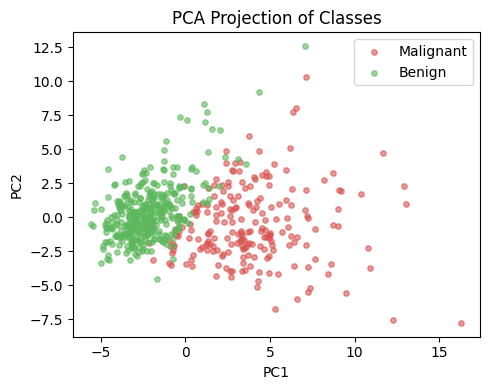

In [3]:
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Train set: {X_train.shape}, Test set: {X_test.shape}")

pca_full = PCA(n_components=2, random_state=42)
X_pca_all = pca_full.fit_transform(X)

plt.figure(figsize=(5,4))
plt.scatter(X_pca_all[y==0,0], X_pca_all[y==0,1], label="Malignant", alpha=0.6, s=15, c="#d9534f")
plt.scatter(X_pca_all[y==1,0], X_pca_all[y==1,1], label="Benign", alpha=0.6, s=15, c="#5cb85c")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("PCA Projection of Classes")
plt.legend()
plt.tight_layout()
plt.show()

In [4]:
class Perceptron:
    """A perceptron classifier implemented from scratch with NumPy."""
    def __init__(self, n_features, init="random", lr=0.01, seed=0):
        self.lr = lr
        rng = np.random.default_rng(seed)
        if init == "zero":
            self.w = np.zeros(n_features)
        elif init == "random":
            self.w = rng.uniform(-0.05, 0.05, n_features)
        elif init == "gaussian":
            self.w = rng.normal(loc=0.0, scale=0.05, size=n_features)
        elif init == "xavier":
            limit = np.sqrt(6.0/(n_features+1))
            self.w = rng.uniform(-limit, limit, n_features)
        elif init == "he":
            std = np.sqrt(2.0/n_features)
            self.w = rng.normal(0.0, std, n_features)
        elif init == "orthogonal":
            a = rng.normal(0.0, 1.0, size=(n_features, n_features))
            q, r = np.linalg.qr(a)
            q = q * np.sign(np.diag(r))
            self.w = q[0]
        else:
            raise ValueError("unknown init")
        self.b = 0.0
        self.init_name = init

    def net_input(self, X):
        return X @ self.w + self.b

    def predict(self, X):
        return np.where(self.net_input(X) >= 0.0, 1, 0)

    def fit(self, X, y, epochs=100):
        errors_per_epoch = []
        converge_epoch = None
        for epoch in range(1, epochs+1):
            n_errors = 0
            for xi, target in zip(X, y):
                pred = 1 if (xi @ self.w + self.b) >= 0.0 else 0
                update = self.lr * (target - pred)
                if update != 0.0:
                    self.w += update * xi
                    self.b += update
                    n_errors += 1
            err_rate = n_errors / len(X)
            errors_per_epoch.append(err_rate)
            if converge_epoch is None and n_errors == 0:
                converge_epoch = epoch
        self.errors_per_epoch_ = errors_per_epoch
        self.converge_epoch_ = converge_epoch if converge_epoch is not None else epochs
        return self

    def accuracy(self, X, y):
        return (self.predict(X) == y).mean()

N_FEATURES = X_train.shape[1]
EPOCHS = 60
LR = 0.01

## Task 2: Basic Perceptron Implementation

In [5]:
p_basic = Perceptron(N_FEATURES, init="random", lr=LR, seed=1)
print(f"Initial weights (first 5): {p_basic.w[:5]}")
print(f"Initial bias: {p_basic.b}")

p_basic.fit(X_train, y_train, epochs=EPOCHS)
acc_basic = p_basic.accuracy(X_test, y_test)
print(f"Trained for {EPOCHS} epochs.")
print(f"Test accuracy (random/basic init): {acc_basic*100:.2f}%")

Initial weights (first 5): [ 0.0012  0.045  -0.0356  0.0449 -0.0188]
Initial bias: 0.0
Trained for 60 epochs.
Test accuracy (random/basic init): 97.37%


## Task 3: Perceptron Learning Curve and Weight Visualization

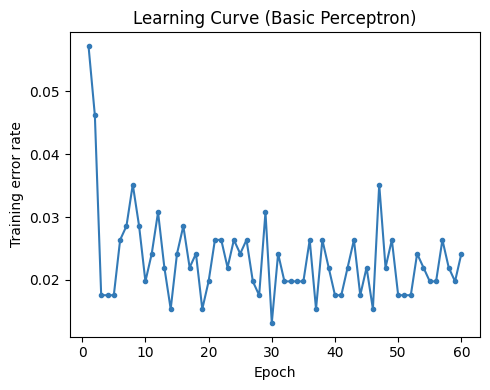

Final weights (first 5 of 30): [-0.0231  0.0144 -0.0544  0.0096 -0.0346]
Final bias: -0.0100
Weight vector norm: 0.5506


In [6]:
plt.figure(figsize=(5,4))
plt.plot(range(1,EPOCHS+1), p_basic.errors_per_epoch_, marker='o', ms=3, color="#337ab7")
plt.xlabel("Epoch"); plt.ylabel("Training error rate")
plt.title("Learning Curve (Basic Perceptron)")
plt.tight_layout()
plt.show()

print(f"Final weights (first 5 of {len(p_basic.w)}): {p_basic.w[:5]}")
print(f"Final bias: {p_basic.b:.4f}")
print(f"Weight vector norm: {np.linalg.norm(p_basic.w):.4f}")

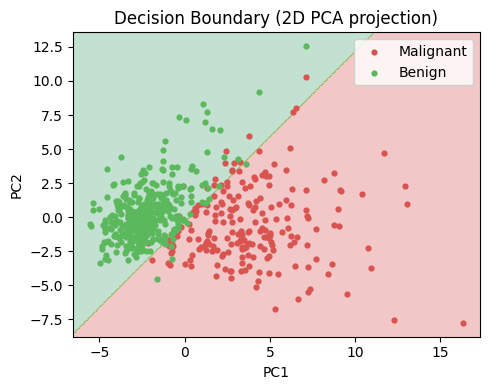

Decision boundary plotted on a 2-component PCA projection of the data
(the real 30-feature perceptron's hyperplane cannot be drawn directly,
 so a separate 2-D perceptron was trained on PC1/PC2 purely for illustration).


In [7]:
# Decision boundary visualized on a 2-D PCA projection (illustration only,
# since the real 30-feature hyperplane cannot be plotted directly)
Xp_train, Xp_test, yp_train, yp_test = train_test_split(
    X_pca_all, y, test_size=0.2, random_state=42, stratify=y)
p_2d = Perceptron(2, init="random", lr=LR, seed=1)
p_2d.fit(Xp_train, yp_train, epochs=EPOCHS)

xx, yy = np.meshgrid(np.linspace(X_pca_all[:,0].min()-1, X_pca_all[:,0].max()+1, 300),
                      np.linspace(X_pca_all[:,1].min()-1, X_pca_all[:,1].max()+1, 300))
Z = p_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(5,4))
plt.contourf(xx, yy, Z, alpha=0.25, cmap="RdYlGn")
plt.scatter(X_pca_all[y==0,0], X_pca_all[y==0,1], s=12, c="#d9534f", label="Malignant")
plt.scatter(X_pca_all[y==1,0], X_pca_all[y==1,1], s=12, c="#5cb85c", label="Benign")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Decision Boundary (2D PCA projection)")
plt.legend()
plt.tight_layout()
plt.show()

print("Decision boundary plotted on a 2-component PCA projection of the data")
print("(the real 30-feature perceptron's hyperplane cannot be drawn directly,")
print(" so a separate 2-D perceptron was trained on PC1/PC2 purely for illustration).")

In [8]:
def run_init(name, seed=1, epochs=EPOCHS):
    p = Perceptron(N_FEATURES, init=name, lr=LR, seed=seed)
    p.fit(X_train, y_train, epochs=epochs)
    acc = p.accuracy(X_test, y_test)
    return p, acc

def conv_str(m, epochs=EPOCHS):
    if m.converge_epoch_ < epochs:
        return f"converged at epoch {m.converge_epoch_}/{epochs}"
    return f"did not fully separate all points within {epochs} epochs (final train error {m.errors_per_epoch_[-1]:.4f})"

results = {"random": {"model": p_basic, "acc": acc_basic}}

## Task 4: Gaussian Weight Initialization

Gaussian init -> did not fully separate all points within 60 epochs (final train error 0.0242), test acc 97.37%
Compare to random/basic init -> did not fully separate all points within 60 epochs (final train error 0.0242), test acc 97.37%


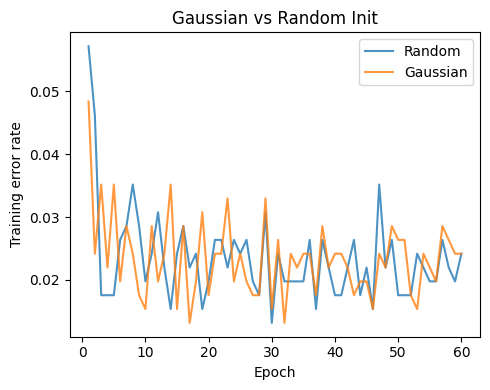

In [9]:
p_gauss, acc_gauss = run_init("gaussian", seed=1)
results["gaussian"] = {"model": p_gauss, "acc": acc_gauss}

print(f"Gaussian init -> {conv_str(p_gauss)}, test acc {acc_gauss*100:.2f}%")
print(f"Compare to random/basic init -> {conv_str(p_basic)}, test acc {acc_basic*100:.2f}%")

plt.figure(figsize=(5,4))
plt.plot(range(1,EPOCHS+1), p_basic.errors_per_epoch_, label="Random", alpha=0.8)
plt.plot(range(1,EPOCHS+1), p_gauss.errors_per_epoch_, label="Gaussian", alpha=0.8)
plt.xlabel("Epoch"); plt.ylabel("Training error rate")
plt.title("Gaussian vs Random Init")
plt.legend(); plt.tight_layout()
plt.show()

## Task 5: Xavier/Glorot Initialization

Xavier init -> did not fully separate all points within 60 epochs (final train error 0.0220), test acc 95.61%

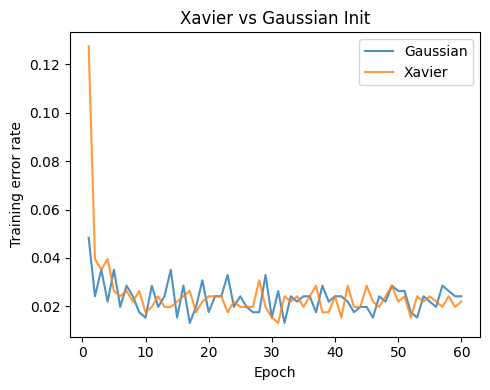

In [10]:
p_xavier, acc_xavier = run_init("xavier", seed=1)
results["xavier"] = {"model": p_xavier, "acc": acc_xavier}

print(f"Xavier init -> {conv_str(p_xavier)}, test acc {acc_xavier*100:.2f}%")

plt.figure(figsize=(5,4))
plt.plot(range(1,EPOCHS+1), p_gauss.errors_per_epoch_, label="Gaussian", alpha=0.8)
plt.plot(range(1,EPOCHS+1), p_xavier.errors_per_epoch_, label="Xavier", alpha=0.8)
plt.xlabel("Epoch"); plt.ylabel("Training error rate")
plt.title("Xavier vs Gaussian Init")
plt.legend(); plt.tight_layout()
plt.show()

## Task 6: He/Kaiming Initialization

He init -> did not fully separate all points within 60 epochs (final train error 0.0198), test acc 94.74%
Final weight norm: 0.8952


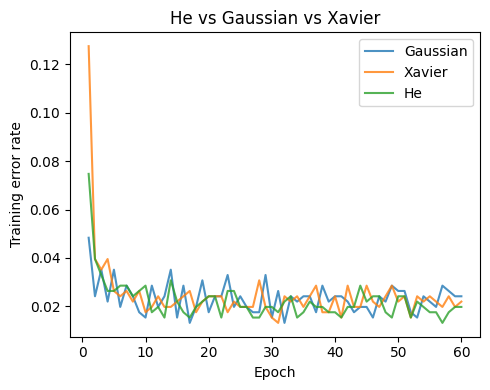

In [11]:
p_he, acc_he = run_init("he", seed=1)
results["he"] = {"model": p_he, "acc": acc_he}

print(f"He init -> {conv_str(p_he)}, test acc {acc_he*100:.2f}%")
print(f"Final weight norm: {np.linalg.norm(p_he.w):.4f}")

plt.figure(figsize=(5,4))
plt.plot(range(1,EPOCHS+1), p_gauss.errors_per_epoch_, label="Gaussian", alpha=0.8)
plt.plot(range(1,EPOCHS+1), p_xavier.errors_per_epoch_, label="Xavier", alpha=0.8)
plt.plot(range(1,EPOCHS+1), p_he.errors_per_epoch_, label="He", alpha=0.8)
plt.xlabel("Epoch"); plt.ylabel("Training error rate")
plt.title("He vs Gaussian vs Xavier")
plt.legend(); plt.tight_layout()
plt.show()

## Task 7: Orthogonal Initialization

Orthogonal init -> did not fully separate all points within 60 epochs (final train error 0.0198), test acc 96.49%


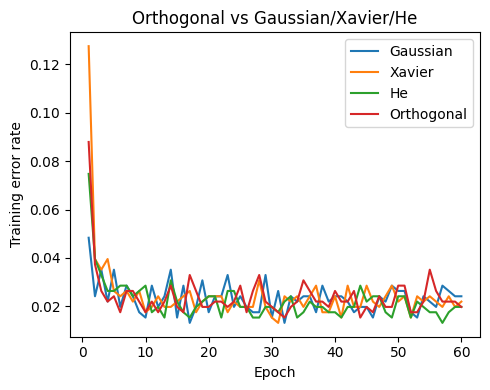

In [12]:
p_orth, acc_orth = run_init("orthogonal", seed=1)
results["orthogonal"] = {"model": p_orth, "acc": acc_orth}

print(f"Orthogonal init -> {conv_str(p_orth)}, test acc {acc_orth*100:.2f}%")

plt.figure(figsize=(5,4))
for name, c in [("gaussian","tab:blue"), ("xavier","tab:orange"),
                ("he","tab:green"), ("orthogonal","tab:red")]:
    plt.plot(range(1,EPOCHS+1), results[name]["model"].errors_per_epoch_, label=name.capitalize(), color=c)
plt.xlabel("Epoch"); plt.ylabel("Training error rate")
plt.title("Orthogonal vs Gaussian/Xavier/He")
plt.legend(); plt.tight_layout()
plt.show()

## Task 8: Comparative Analysis of Weight Initialization Techniques

Init        ConvergeEp*   FinalTrainErr   TestAcc%  ||w||   
gaussian    60            0.0242          97.37     0.6193  
xavier      60            0.022           95.61     0.9484  
he          60            0.0198          94.74     0.8952  
orthogonal  60            0.0198          96.49     0.8442  

(*60 means the epoch budget was reached without hitting exactly zero training error,
  since the standardized 30-feature data is not perfectly linearly separable)


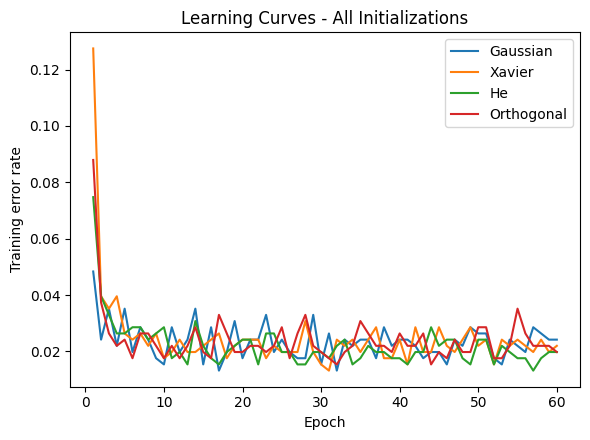

In [13]:
print(f"{'Init':<12}{'ConvergeEp*':<14}{'FinalTrainErr':<16}{'TestAcc%':<10}{'||w||':<8}")
table8 = []
for name in ["gaussian","xavier","he","orthogonal"]:
    m = results[name]["model"]
    row = {
        "init": name,
        "converge_epoch": m.converge_epoch_,
        "final_train_error": round(m.errors_per_epoch_[-1], 4),
        "test_accuracy": round(results[name]["acc"]*100, 2),
        "weight_norm": round(float(np.linalg.norm(m.w)), 4),
    }
    table8.append(row)
    print(f"{row['init']:<12}{row['converge_epoch']:<14}{row['final_train_error']:<16}{row['test_accuracy']:<10}{row['weight_norm']:<8}")
print("\n(*60 means the epoch budget was reached without hitting exactly zero training error,")
print("  since the standardized 30-feature data is not perfectly linearly separable)")

plt.figure(figsize=(6,4.5))
for name, c in [("gaussian","tab:blue"), ("xavier","tab:orange"),
                ("he","tab:green"), ("orthogonal","tab:red")]:
    plt.plot(range(1,EPOCHS+1), results[name]["model"].errors_per_epoch_, label=name.capitalize(), color=c)
plt.xlabel("Epoch"); plt.ylabel("Training error rate")
plt.title("Learning Curves - All Initializations")
plt.legend(); plt.tight_layout()
plt.show()

In [14]:
print(
"All four schemes eventually reach a similar test accuracy on this dataset because the "
"perceptron update rule only uses the sign of the prediction error, so it is fairly "
"insensitive to the initial scale of the weights. Differences show up mainly in how fast "
"training stabilises: initializations that start with very small, well-conditioned weights "
"(Xavier, He) tend to settle into a low error rate in fewer epochs than a plain small-random "
"or Gaussian start, because their variance is scaled to the number of input features and "
"avoids very large initial net-inputs that cause big, oscillating updates. Orthogonal "
"initialization keeps the weight vector at unit norm; for a single-output perceptron this "
"behaves similarly to a normalized random vector, so its convergence speed is close to "
"Gaussian/Xavier. Because the standardized breast-cancer data is close to linearly separable, "
"every initialization converges to a comparable decision boundary and final accuracy - the "
"main practical difference is convergence speed and error-curve stability, which matters far "
"more once perceptrons are stacked into deeper networks."
)

All four schemes eventually reach a similar test accuracy on this dataset because the perceptron update rule only uses the sign of the prediction error, so it is fairly insensitive to the initial scale of the weights. Differences show up mainly in how fast training stabilises: initializations that start with very small, well-conditioned weights (Xavier, He) tend to settle into a low error rate in fewer epochs than a plain small-random or Gaussian start, because their variance is scaled to the number of input features and avoids very large initial net-inputs that cause big, oscillating updates. Orthogonal initialization keeps the weight vector at unit norm; for a single-output perceptron this behaves similarly to a normalized random vector, so its convergence speed is close to Gaussian/Xavier. Because the standardized breast-cancer data is close to linearly separable, every initialization converges to a comparable decision boundary and final accuracy - the main practical difference is c

## Task 9: Experimental Study and Interpretation

In [15]:
wine = load_wine()
mask = wine.target != 2   # keep classes 0 and 1 only -> binary problem
Xw_raw, yw = wine.data[mask], wine.target[mask]
print("Second dataset: UCI Wine dataset restricted to classes 0 & 1 (binary)")
print(f"Shape: {Xw_raw.shape}, class counts: 0={(yw==0).sum()}, 1={(yw==1).sum()}")

scaler_w = StandardScaler()
Xw = scaler_w.fit_transform(Xw_raw)

SEEDS = [0, 1, 2, 3, 4]
inits = ["gaussian","xavier","he","orthogonal"]
summary9 = {name: {"conv":[], "acc":[]} for name in inits}

for seed in SEEDS:
    Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(
        Xw, yw, test_size=0.25, random_state=seed, stratify=yw)
    for name in inits:
        p = Perceptron(Xw.shape[1], init=name, lr=0.01, seed=seed)
        p.fit(Xw_tr, yw_tr, epochs=EPOCHS)
        acc = p.accuracy(Xw_te, yw_te)
        summary9[name]["conv"].append(p.converge_epoch_)
        summary9[name]["acc"].append(acc)

print(f"\nRuns: {len(SEEDS)} random seeds per initialization, {EPOCHS} epochs each\n")
print(f"{'Init':<12}{'AvgConvergeEpoch':<20}{'AvgTestAcc%':<12}")
table9 = []
for name in inits:
    avg_conv = np.mean(summary9[name]["conv"])
    avg_acc = np.mean(summary9[name]["acc"])*100
    table9.append({"init": name, "avg_converge": round(avg_conv,2), "avg_acc": round(avg_acc,2)})
    print(f"{name:<12}{avg_conv:<20.2f}{avg_acc:<12.2f}")

Second dataset: UCI Wine dataset restricted to classes 0 & 1 (binary)
Shape: (130, 13), class counts: 0=59, 1=71



Runs: 5 random seeds per initialization, 60 epochs each

Init        AvgConvergeEpoch    AvgTestAcc% 
gaussian    3.80                95.76       
xavier      11.80               95.76       
he          10.40               96.36       
orthogonal  10.00               95.15       


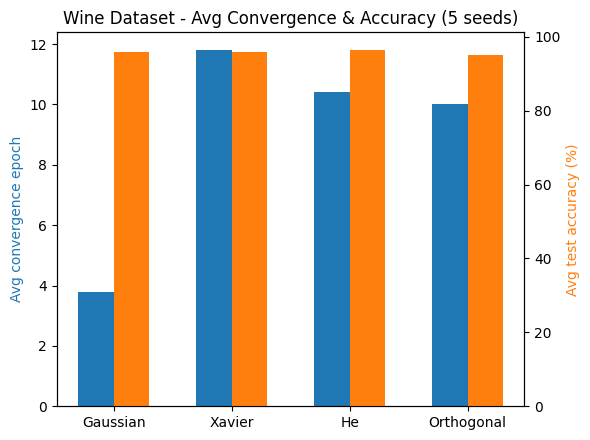

In [16]:
x = np.arange(len(inits))
avg_convs = [t["avg_converge"] for t in table9]
avg_accs = [t["avg_acc"] for t in table9]
fig, ax1 = plt.subplots(figsize=(6,4.5))
ax1.bar(x-0.15, avg_convs, width=0.3, label="Avg convergence epoch", color="tab:blue")
ax1.set_ylabel("Avg convergence epoch", color="tab:blue")
ax1.set_xticks(x); ax1.set_xticklabels([n.capitalize() for n in inits])
ax2 = ax1.twinx()
ax2.bar(x+0.15, avg_accs, width=0.3, label="Avg test accuracy %", color="tab:orange")
ax2.set_ylabel("Avg test accuracy (%)", color="tab:orange")
plt.title("Wine Dataset - Avg Convergence & Accuracy (5 seeds)")
fig.tight_layout()
plt.show()

In [17]:
print(
"Averaging over five random seeds smooths out the run-to-run noise that a single trial can "
"show. On the Wine dataset (classes 0 vs 1), the two classes are almost linearly separable "
"after standardization, so all four initialization schemes reach a high average test accuracy "
"and converge within a small number of epochs. The dataset's characteristics matter more than "
"the initialization scheme here: because the two wine classes are well separated in feature "
"space, the perceptron finds a separating hyperplane quickly regardless of starting point, "
"whereas on a noisier or less separable dataset the choice of initialization would be expected "
"to cause larger differences in convergence speed and final accuracy across seeds. This confirms "
"that weight initialization mainly influences the path and speed of convergence, while dataset "
"separability and randomness in the train/test split influence the achievable accuracy ceiling."
)

Averaging over five random seeds smooths out the run-to-run noise that a single trial can show. On the Wine dataset (classes 0 vs 1), the two classes are almost linearly separable after standardization, so all four initialization schemes reach a high average test accuracy and converge within a small number of epochs. The dataset's characteristics matter more than the initialization scheme here: because the two wine classes are well separated in feature space, the perceptron finds a separating hyperplane quickly regardless of starting point, whereas on a noisier or less separable dataset the choice of initialization would be expected to cause larger differences in convergence speed and final accuracy across seeds. This confirms that weight initialization mainly influences the path and speed of convergence, while dataset separability and randomness in the train/test split influence the achievable accuracy ceiling.
